In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy.optimize import minimize_scalar
from scipy.optimize import minimize
np.set_printoptions(legacy='1.21')

In [2]:
#Function defined in previous class
def portfolio_volatility(weights, std_devs, corr_matrix):
    w = np.asarray(weights)
    s = np.asarray(std_devs)
    C = np.asarray(corr_matrix)
    D = np.diag(s)
    Sigma = D @ C @ D
    var_p = w.T @ Sigma @ w
    vol_p = np.sqrt(var_p)
    return vol_p

In [3]:
# Portfolio expected return. Vector of weights and return 
#must have the same size
def expret(weights,returns):
    w = np.asarray(weights)
    r = np.asarray(returns)
    return w.T@r

In [4]:
#Example 1
expret([0.5,0.5],[0.2,0.3])

0.25

In [5]:
#Example 2
x=(1/3,1/6,1/2)
ret=(0.08,0.09,0.2)
expret(x,ret)

0.14166666666666666

In [6]:
#Compute optimal portfolio weights maximizing expected return
#subject to volatility constraint and 0 <= w_i <= 1, sum(w)=1.
#Parameters:
# r : array-like, shape (n,1)          Expected returns of assets.
# Sigma : array-like, shape (n, n)     Covariance matrix of asset returns.
#sigma_max : float                     Maximum allowed portfolio volatility.
      
def optimal_portfolio(r, Sigma, sigma_max):
    mu = np.array(r)
    Sigma = np.array(Sigma)
    n = len(mu)
    # Objective function: negative expected return (for minimization)
    def objective(w):
        return -mu @ w    
    # Constraint: volatility <= sigma_max
    def volatility_constraint(w):
        return sigma_max - np.sqrt(w @ Sigma @ w)  
    # Constraint: sum of weights = 1
    def weight_sum_constraint(w):
        return np.sum(w) - 1.0
    # Initial guess: equally weighted portfolio
    w0 = np.ones(n) / n
    # Bounds: 0 <= w_i <= 1
    bounds = [(0.0, 1.0) for _ in range(n)]
    # Define constraints dictionary for optimizer
    constraints = [
        {'type': 'eq', 'fun': weight_sum_constraint},
        {'type': 'ineq', 'fun': volatility_constraint}
    ]
    # Optimization
    result = minimize(objective, w0, bounds=bounds, constraints=constraints)
    if not result.success:
        raise ValueError("Optimization failed:", result.message)
    return result.x

In [7]:
# An example
r = np.array([0.08, 0.12, 0.15])  # Expected returns
Sigma = np.array([                # Covariance matrix
    [0.04, 0.01, 0.02],
    [0.01, 0.09, 0.03],
    [0.02, 0.03, 0.16]
])
sigma_max = 0.20                  # Constraint on volatility
w_opt = optimal_portfolio(r, Sigma, sigma_max)

In [8]:
w_opt

array([0.38731011, 0.36140799, 0.25128189])

In [9]:
# Version without limits on digits after zero

print("Optimal weights:", w_opt)
print("Expected return:", r @ w_opt)
print("Volatility:", np.sqrt(w_opt @ Sigma @ w_opt))


Optimal weights: [0.38731011 0.36140799 0.25128189]
Expected return: 0.11204605229085948
Volatility: 0.20000003251199258


In [10]:
# Version with limits on digits after zero

print("Optimal weights:", np.round(w_opt, 4))
print("Expected return:", np.round(r @ w_opt, 5))
print("Volatility:", np.round(np.sqrt(w_opt @ Sigma @ w_opt), 5))

Optimal weights: [0.3873 0.3614 0.2513]
Expected return: 0.11205
Volatility: 0.2


In [11]:
#Now consider the problem of minimizing volatility for a given target on expected returns
#No short sales.   0 <= w_i <= 1 and sum(w)=1.
def min_volatility_portfolio(r, Sigma, target_return):
    mu = np.array(r)
    Sigma = np.array(Sigma)
    n = len(mu)
    # Objective: minimize portfolio volatility (standard deviation)
    def objective(w):
        return np.sqrt(w @ Sigma @ w)
    # Constraint: expected return >= target_return
    def return_constraint(w):
        return mu @ w - target_return
    # Constraint: sum of weights = 1
    def weight_sum_constraint(w):
        return np.sum(w) - 1.0
    # Initial guess and bounds
    w0 = np.ones(n) / n
    bounds = [(0.0, 1.0) for _ in range(n)]    
    constraints = [
        {'type': 'eq', 'fun': weight_sum_constraint},
        {'type': 'ineq', 'fun': return_constraint}
    ]
    result = minimize(objective, w0, bounds=bounds, constraints=constraints)
    if not result.success:
        raise ValueError("Optimization failed:", result.message)    
    return result.x

In [12]:
# Example
r = np.array([0.08, 0.12, 0.15])  # Expected returns
S = np.array([                    # Covariance matrix
    [0.04, 0.01, 0.02],
    [0.01, 0.09, 0.03],
    [0.02, 0.03, 0.16]
])
min_volatility_portfolio(r, S, 0.13)

array([0.08182817, 0.47573428, 0.44243755])

In [13]:
#Expected return under the minimum volatility portfolio

w=min_volatility_portfolio(r, S, 0.13)
w@r

0.12999999994146455

In [14]:
np.sqrt(w.T@S@w)

0.25848163899637194

In [15]:
# Range of target returns
target_returns = np.linspace(0.08, 0.15, 30)

# Store results
frontier_vols = []
frontier_rets = []

for r_target in target_returns:
    w = min_volatility_portfolio(r, Sigma, r_target)
    port_ret = r @ w
    port_vol = np.sqrt(w @ S @ w)
    frontier_rets.append(port_ret)
    frontier_vols.append(port_vol)

In [16]:
target_returns

array([0.08      , 0.08241379, 0.08482759, 0.08724138, 0.08965517,
       0.09206897, 0.09448276, 0.09689655, 0.09931034, 0.10172414,
       0.10413793, 0.10655172, 0.10896552, 0.11137931, 0.1137931 ,
       0.1162069 , 0.11862069, 0.12103448, 0.12344828, 0.12586207,
       0.12827586, 0.13068966, 0.13310345, 0.13551724, 0.13793103,
       0.14034483, 0.14275862, 0.14517241, 0.14758621, 0.15      ])

In [17]:
print(frontier_vols[0])
print(frontier_rets[0])
print(frontier_vols[10])
print(frontier_rets[10])
print(frontier_vols[20])
print(frontier_rets[20])

0.17677671805094253
0.09438801707905532
0.18417605232275497
0.10413793105563658
0.25190030474119207
0.12827586213945108


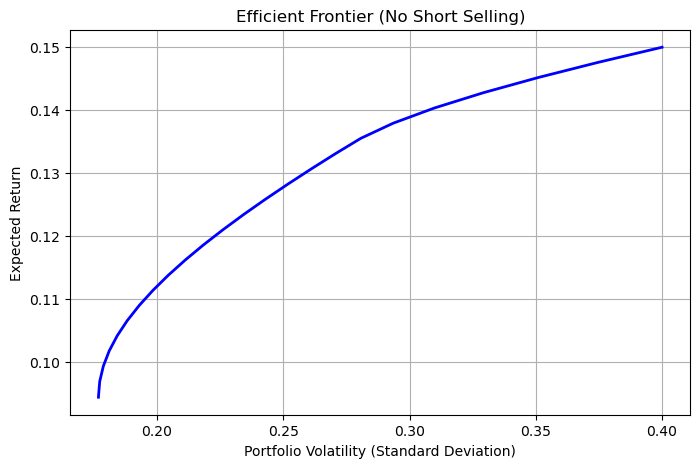

In [18]:
# ===== Plot Efficient Frontier =====
plt.figure(figsize=(8,5))
plt.plot(frontier_vols, frontier_rets, 'b-', lw=2)
plt.title("Efficient Frontier (No Short Selling)")
plt.xlabel("Portfolio Volatility (Standard Deviation)")
plt.ylabel("Expected Return")
plt.grid(True)
plt.show()

In [19]:
#Computing the inverse of a matrix
A=([2,0],[0,5])
np.linalg.inv(A)

array([[0.5, 0. ],
       [0. , 0.2]])

In [20]:
#Compute the Global Minimum Variance (GMV) portfolio.
#Short selling allowed.

def global_min_variance_portfolio(Sigma):
    n = Sigma.shape[0]
    Sigma_inv = np.linalg.inv(Sigma)
    ones = np.ones(n)  
    w_gmv = Sigma_inv @ ones
    w_gmv /= np.sum(w_gmv)
    return w_gmv

In [21]:
S = np.array([
    [0.04, 0.01, 0.02],
    [0.01, 0.1, 0.03],
    [0.02, 0.03, 0.16]
])

global_min_variance_portfolio(S)

array([0.70454545, 0.22727273, 0.06818182])

In [22]:
w=global_min_variance_portfolio(S)
np.sqrt(w.T @ S @ w)

0.17837651700316892

In [23]:
#Compute the minimum-variance portfolio achieving a target return.
#Short selling is allowed.

def min_var_portfolio(r, Sigma, target_return):
    n = len(r)
    mu = np.array(r)
    Sigma = np.array(Sigma)
    Sigma_inv = np.linalg.inv(Sigma)

    A = mu @ Sigma_inv @ mu
    B = mu @ Sigma_inv @ np.ones(n)
    C = np.ones(n) @ Sigma_inv @ np.ones(n)
    D = A * C - B**2

    lambda1 = (C * target_return - B) / D
    lambda2 = (A - B * target_return) / D
    w = Sigma_inv @ (lambda1 * mu + lambda2 * np.ones(n))
    return w

In [24]:
#Example 
min_var_portfolio(r, S, 0.08)

array([ 0.93709677,  0.14677419, -0.08387097])